# 2장 2강: 시계열 데이터 모델링과 예측

## 실습 목표

이번 실습에서는 **Bike Sharing Demand** 데이터를 이용하여 시계열 예측의 기본 흐름을 연습합니다.

- 시간 순서를 유지하면서 **Train / Test 데이터**를 분리합니다.
- **AR, I, MA**가 무엇을 의미하는지 확인합니다.
- **ARIMA(2, 1, 1)** 모델을 학습합니다.
- Test 기간의 미래 값을 예측합니다.
- 실제값과 예측값을 비교합니다.
- **MAE, RMSE**를 이용해 예측 성능을 평가합니다.

> 이 실습에서는 2장 2강 교안에 나온 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- statsmodels
- scikit-learn
- 데이터: `Bike_Sharing_Demand.csv`

### 주요 컬럼

| 컬럼 | 의미 |
|---|---|
| `datetime` | 자전거 대여 기록 시각 |
| `casual` | 비등록 사용자 대여 수 |
| `registered` | 등록 사용자 대여 수 |
| `count` | 전체 자전거 대여 수 |

이번 강에서는 월별 대여량 `count`를 시계열로 사용합니다.

## 실습 준비

다음 순서로 데이터를 준비합니다.

1. 데이터 불러오기
2. `datetime` 자료형 확인
3. 결측치 확인
4. `datetime`을 날짜/시간 자료형으로 변환
5. 시간 순서대로 정렬
6. 월별 대여량 `count` 준비

> 월별 집계 코드는 시계열 모델링을 위한 준비 코드로 제공됩니다.

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt

bike = pd.read_csv("Bike_Sharing_Demand.csv")

print("데이터 크기:", bike.shape)
display(bike.head())

print("\n[자료형]")
display(bike[["datetime", "count"]].dtypes.to_frame("dtype"))

print("\n[결측치]")
display(bike[["datetime", "count"]].isna().sum().to_frame("missing"))

데이터 크기: (10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1



[자료형]


,dtype
datetime,str
count,int64



[결측치]


,missing
datetime,0
count,0


In [2]:
bike["datetime"] = pd.to_datetime(bike["datetime"])
bike = bike.sort_values("datetime").reset_index(drop=True)

bike["month"] = (
    bike["datetime"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly = (
    bike.groupby("month", as_index=False)["count"]
    .sum()
)

monthly = monthly.set_index("month")

print("월별 데이터 개수:", len(monthly))
display(monthly.head())
display(monthly.tail())
monthly = monthly.asfreq('MS')

월별 데이터 개수: 24


,count
month,
2011-01-01,23552
2011-02-01,32844
2011-03-01,38735
2011-04-01,50517
2011-05-01,79713


,count
month,
2012-08-01,130220
2012-09-01,133425
2012-10-01,127912
2012-11-01,105551
2012-12-01,98977


---

# 필수 1. 시간 순서를 유지한 Train / Test 분리

## 배경

시계열 데이터에서는 데이터를 무작위로 섞으면 미래 시점의 데이터가 Train에 포함될 수 있습니다.

따라서 **과거 데이터를 Train**, **그 이후 데이터를 Test**로 사용해야 합니다.

이번 실습에서는 월별 대여량의 **마지막 6개월을 Test 데이터**로 사용합니다.

## 문제 1. Train / Test 데이터를 분리하세요.

### 요구사항

1. `monthly`의 마지막 6개 행을 Test 데이터로 사용합니다.
2. 나머지 데이터를 Train 데이터로 사용합니다.
3. Train과 Test의 시작일과 종료일을 출력합니다.
4. Train과 Test를 같은 그래프에 표시합니다.

### 확인 포인트

- 시간 순서를 유지했는가?
- Test 데이터가 Train 데이터보다 뒤의 기간인가?
- 무작위 분리를 사용하지 않았는가?

Train: 2011-01-01 ~ 2012-06-01 18 개월
Test: 2012-07-01 ~ 2012-12-01 6 개월


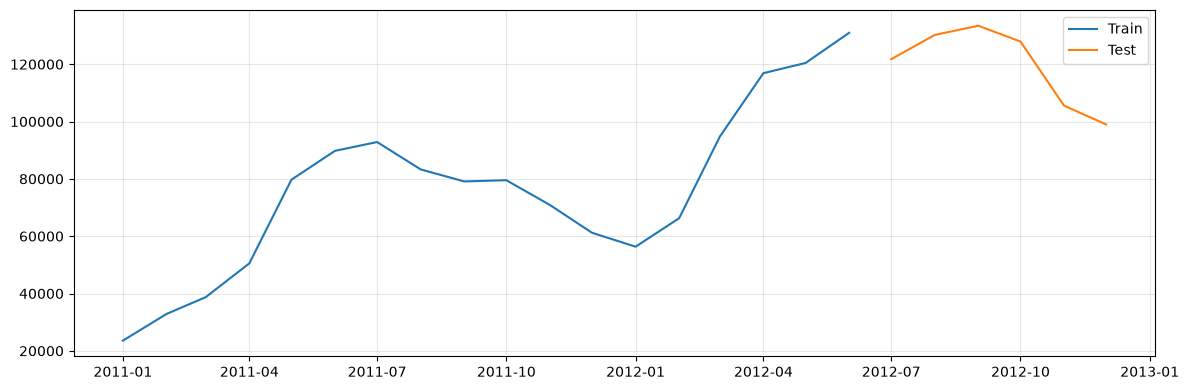

In [3]:
train = monthly.iloc[:-6].copy()
test = monthly.iloc[-6:].copy()
print('Train:',train.index.min().date(),'~',train.index.max().date(),len(train),'개월')
print('Test:',test.index.min().date(),'~',test.index.max().date(),len(test),'개월')
assert train.index.max() < test.index.min()
plt.figure(figsize=(12,4)); plt.plot(train.index,train['count'],label='Train')
plt.plot(test.index,test['count'],label='Test'); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Q1. 시계열 데이터에서 무작위로 Train / Test를 분리하면 안 되는 이유는 무엇인가요?

**답변:**  
미래 관측값이 학습에 들어가면 실제 예측 상황과 달라지고 평가가 낙관적으로 왜곡됩니다. 시간 의존성을 유지하며 과거로 학습하고 이후 기간으로 평가해야 합니다.

---

# 필수 2. ARIMA 모델 학습과 미래 값 예측

## 배경

ARIMA는 다음 세 가지 요소로 구성됩니다.

- **AR(p)**: 과거의 실제 값을 몇 개 사용할 것인가?
- **I(d)**: 차분을 몇 번 적용할 것인가?
- **MA(q)**: 과거의 예측 오차를 몇 개 사용할 것인가?

이번 실습에서는 교안과 동일하게 `ARIMA(2, 1, 1)`을 사용합니다.

## 문제 1. ARIMA(2, 1, 1)의 의미를 설명하세요.

### 요구사항

다음 세 값을 각각 설명합니다.

- `p = 2`
- `d = 1`
- `q = 1`

### Q2. 각각 무엇을 의미하나요?

**답변:**  
p=2는 차분된 시계열의 과거 2개 값에 대한 자기회귀 항, d=1은 원본을 1번 차분하는 설정, q=1은 과거 1개 예측 오차(충격)에 대한 이동평균 항입니다. MA는 관측값의 단순 이동평균과 다릅니다.

## 문제 2. Train 데이터로 ARIMA 모델을 학습하세요.

### 요구사항

1. `statsmodels.tsa.arima.model`에서 `ARIMA`를 불러옵니다.
2. Train 데이터의 `count`를 사용합니다.
3. `order=(2, 1, 1)`을 지정합니다.
4. `fit()`으로 모델을 학습합니다.

### 확인 포인트

- Test 데이터를 학습에 사용하지 않았는가?
- `order=(p, d, q)`의 순서를 알고 있는가?

In [4]:
from statsmodels.tsa.arima.model import ARIMA
model = ARIMA(train['count'], order=(2,1,1))
model_fit = model.fit()
print(model_fit.summary())
print('수렴 여부:', model_fit.mle_retvals.get('converged'))

                               SARIMAX Results                                
Dep. Variable:                  count   No. Observations:                   18
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -180.476
Date:                Fri, 02 Oct 2026   AIC                            368.953
Time:                        17:23:44   BIC                            372.285
Sample:                    01-01-2011   HQIC                           369.284
                         - 06-01-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5770      0.932      0.619      0.536      -1.249       2.403
ar.L2         -0.1038      0.541     -0.192      0.848      -1.165       0.957
ma.L1          0.2235      1.001      0.223      0.8

## 문제 3. Test 기간만큼 미래 값을 예측하세요.

### 요구사항

1. `forecast()`를 사용합니다.
2. `steps=len(test)`로 Test 기간과 같은 개수만큼 예측합니다.
3. 예측값의 인덱스를 Test 데이터의 인덱스와 동일하게 설정합니다.
4. `actual`, `predicted` 컬럼을 가진 DataFrame을 만듭니다.
5. 실제값과 예측값을 같은 그래프에 표시합니다.

### 확인 포인트

- Train 마지막 시점 이후의 값을 예측했는가?
- Test 길이와 예측값 개수가 같은가?
- Actual과 Predicted를 구분했는가?

,actual,predicted
month,,
2012-07-01,121769,139405.880749
2012-08-01,130220,143188.734859
2012-09-01,133425,144494.520944
2012-10-01,127912,144855.327175
2012-11-01,105551,144927.980297
2012-12-01,98977,144932.451482


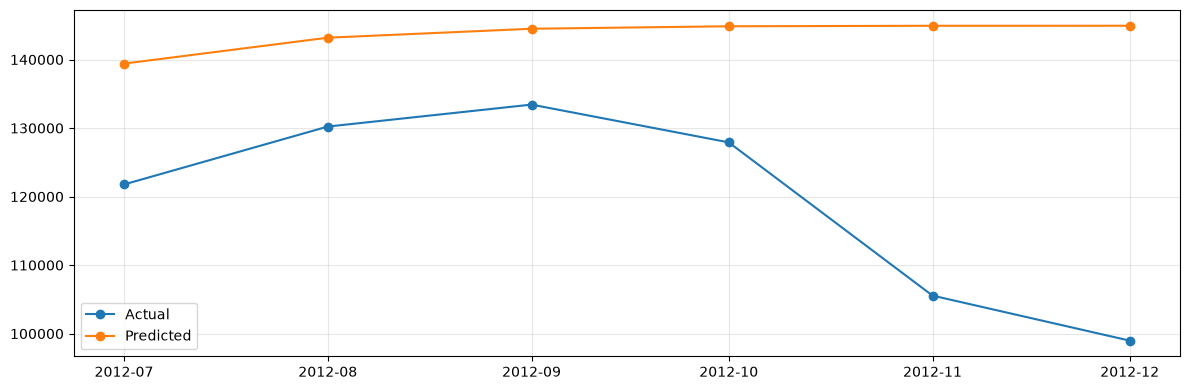

In [5]:
predicted = model_fit.forecast(steps=len(test))
predicted.index = test.index
result = pd.DataFrame({'actual':test['count'],'predicted':predicted})
display(result)
plt.figure(figsize=(12,4)); plt.plot(result.index,result['actual'],marker='o',label='Actual')
plt.plot(result.index,result['predicted'],marker='o',label='Predicted')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### Q3. `steps=len(test)`는 무엇을 의미하나요?

**답변:**  
학습 마지막 시점 다음부터 Test의 관측 개수만큼 예측한다는 뜻입니다. 월별 데이터에서 len(test)=6이므로 다음 6개월을 예측합니다.

### Q4. Actual과 Predicted는 각각 무엇을 의미하나요?

**답변:**  
Actual은 Test 기간에 실제로 관측된 월별 합계이며 Predicted는 Train만으로 학습한 모델이 예측한 같은 기간의 합계입니다.

---

# 과제 1. 정상성 진단을 반영한 ARIMA 예측과 예측 신뢰도 평가

## 배경

필수 1의 Train/Test 분리는 유지합니다. 과제에서는 Train 데이터의 정상성을 먼저 진단한 뒤 ARIMA의 차분 차수 d를 선택하여 모델을 다시 학습합니다. MAE·RMSE와 함께 **95% 예측 구간의 하한·상한**을 실제값과 비교합니다.

## 요구사항

1. 필수 1에서 만든 `train`, `test`를 사용합니다. 정상성 진단과 모델 설정에는 Train만 사용합니다.
2. Train의 `count`와 최근 3개 관측값의 이동평균을 그래프로 확인합니다. 원본에 ADF Test를 수행하고 검정통계량과 p-value를 출력합니다. 짧은 월별 자료이므로 이번 과제의 검정 설정은 `maxlag=1, regression="c", autolag="AIC"`로 통일합니다.
3. 유의수준 0.05에서 원본의 단위근 귀무가설을 기각하면 d=0을 우선 검토합니다. 기각하지 못하면 1차 차분한 Train에 같은 설정으로 ADF Test를 다시 수행하고 차분 그래프를 확인합니다. 차분 후 기각하면 d=1을 선택합니다. 차분 후에도 기각하지 못하면 추가 진단이 필요함을 명시하고, 이번 과제에서는 d=1을 잠정 설정하여 예측 과정과 한계를 함께 평가합니다. 선택 근거에 그래프 해석도 포함합니다.
4. **차분하지 않은 Train의 원본 `count`**를 `ARIMA(order=(2, d, 1))`에 전달해 학습합니다. 차분은 모델 내부에서 처리하므로 차분 데이터에 d=1을 다시 적용하지 않습니다. 필수 2의 모델·결과와 구분하여 과제용 변수를 사용합니다.
5. `get_forecast(steps=len(test))`로 Test 기간의 예측값과 95% 예측 구간을 구합니다. `predicted_mean`과 `conf_int(alpha=0.05)`를 활용합니다.
6. Test 날짜에 맞춰 `actual`, `predicted`, `lower_95`, `upper_95`를 가진 `task_result`를 만들고 출력합니다.
7. 과제 모델의 MAE·RMSE를 계산하고 의미를 설명합니다.
8. 실제값·예측값·95% 예측 구간을 같은 그래프에 표시합니다. 시점별 구간 폭과 실제값의 구간 포함 여부를 표에 추가하고, 구간 밖인 시점을 확인합니다.
9. 실제값과 구간의 비교 및 구간 폭을 근거로 예측 신뢰도를 해석합니다. 신뢰도가 낮다고 판단한 구간의 가능한 원인 또는 모델의 한계를 한 가지 이상 설명합니다. 구간 밖인 시점이 없더라도 구간 폭과 자료의 한계를 검토합니다.

> Test는 최종 평가에만 사용합니다. Test 결과를 보고 d나 다른 모델 설정을 다시 선택하지 않습니다. 월별 값은 제공된 CSV의 관측값 합계이며, 월 전체 날짜가 없으면 완전한 월간 총수요로 해석하지 않습니다.

### 확인 포인트

- Train만으로 정상성을 진단하고 d 선택 근거를 제시했는가?
- 1차 차분 후에도 귀무가설을 기각하지 못한 경우 잠정 모델의 한계를 밝혔는가?
- 원본 Train을 모델에 입력하여 이중 차분을 피했는가?
- MAE·RMSE와 실제값·예측값·예측 구간을 함께 확인했는가?
- 구간 밖 실제값과 구간 폭을 근거로 예측 신뢰도와 한계를 설명했는가?
- Q5~Q9에 모두 답했는가?


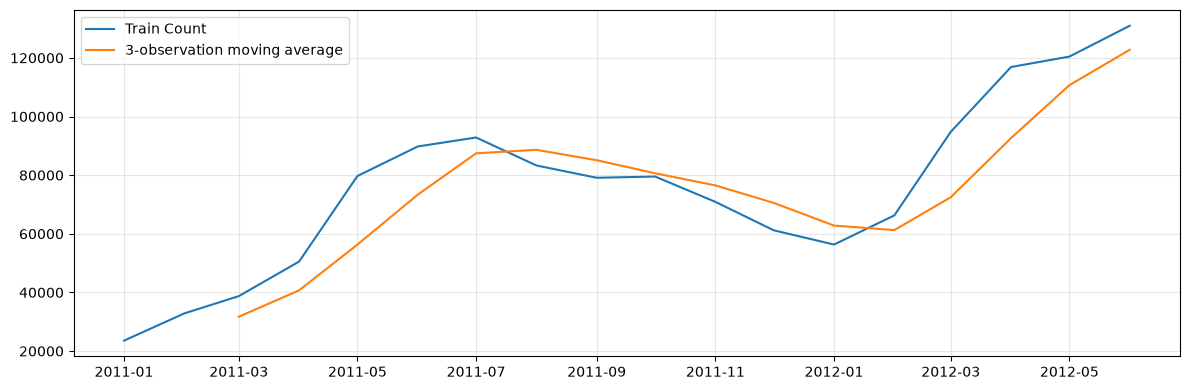

원본 ADF=-1.571055, p=0.498115


C:\Users\tae37\AppData\Local\Temp\ipykernel_12856\2475366087.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  task_adf_original = adfuller(train['count'], maxlag=1, regression='c', autolag='AIC')
C:\Users\tae37\AppData\Local\Temp\ipykernel_12856\2475366087.py:15: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  task_adf_diff = adfuller(task_diff,maxlag=1,regression='c',au

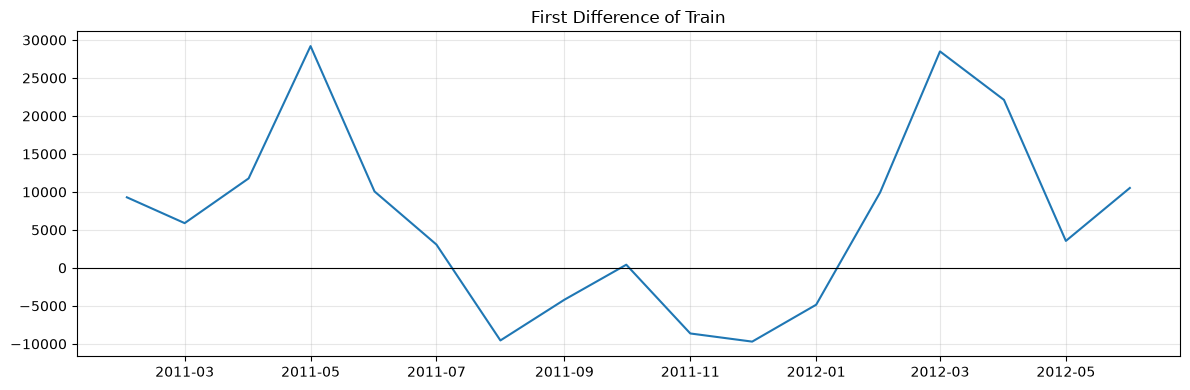

차분 ADF=-1.981417, p=0.29478
차분 후에도 기각하지 못함: 추가 진단 필요, d=1 잠정 선택
원본과 이동평균에 상승 및 계절 변동이 보이고, 차분에도 패턴이 남을 수 있습니다.
과제 모델 수렴 여부: True


,actual,predicted,lower_95,upper_95,interval_width,inside_95
month,,,,,,
2012-07-01,121769,139405.880749,121498.779335,157312.982163,35814.202828,True
2012-08-01,130220,143188.734859,106308.088273,180069.381446,73761.293173,True
2012-09-01,133425,144494.520944,91068.735687,197920.306200,106851.570514,True
2012-10-01,127912,144855.327175,77591.955731,212118.698619,134526.742888,True
2012-11-01,105551,144927.980297,65904.510142,223951.450453,158046.940311,True
2012-12-01,98977,144932.451482,55628.120917,234236.782048,178608.661131,True


MAE=23991.82, RMSE=27541.81
구간 밖 시점: []


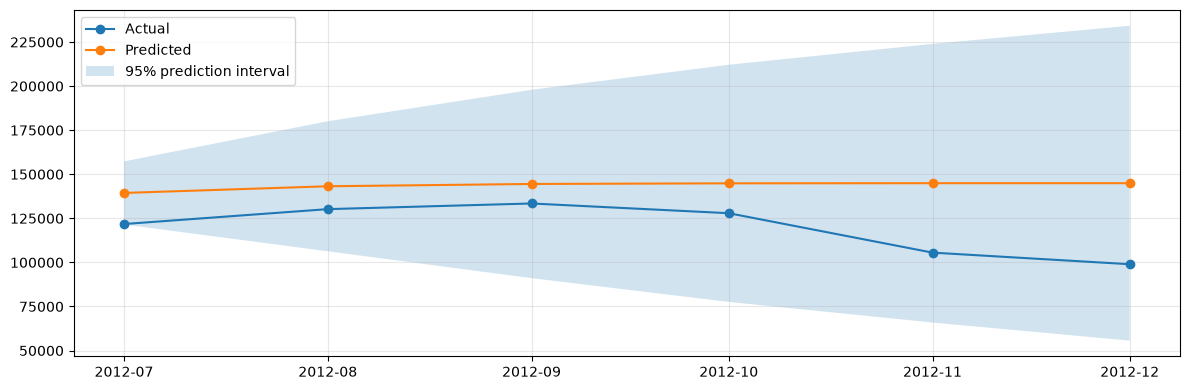

구간 포함률: 1.0
넓은 예측 구간은 불확실성이 크다는 뜻이며, 구간 내 실제값만으로 높은 정확도를 주장할 수 없습니다.


In [7]:
import numpy as np
from statsmodels.tsa.stattools import adfuller
train_rolling = train['count'].rolling(window=3).mean()
plt.figure(figsize=(12,4)); plt.plot(train.index,train['count'],label='Train Count')
plt.plot(train.index,train_rolling,label='3-observation moving average')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
task_adf_original = adfuller(train['count'], maxlag=1, regression='c', autolag='AIC')
print(f'원본 ADF={task_adf_original[0]:.6f}, p={task_adf_original[1]:.6g}')
task_adf_diff = None
if task_adf_original[1] < .05:
    task_d = 0
    print('원본 귀무가설 기각: d=0 선택')
else:
    task_diff = train['count'].diff().dropna()
    task_adf_diff = adfuller(task_diff,maxlag=1,regression='c',autolag='AIC')
    plt.figure(figsize=(12,4)); plt.plot(task_diff.index,task_diff)
    plt.axhline(0,color='black',lw=.8); plt.title('First Difference of Train')
    plt.grid(alpha=.3); plt.tight_layout(); plt.show()
    print(f'차분 ADF={task_adf_diff[0]:.6f}, p={task_adf_diff[1]:.6g}')
    task_d = 1
    print('차분 후 기각: d=1 선택' if task_adf_diff[1]<.05 else '차분 후에도 기각하지 못함: 추가 진단 필요, d=1 잠정 선택')
print('원본과 이동평균에 상승 및 계절 변동이 보이고, 차분에도 패턴이 남을 수 있습니다.')
task_model = ARIMA(train['count'],order=(2,task_d,1))
task_fit = task_model.fit()
print('과제 모델 수렴 여부:',task_fit.mle_retvals.get('converged'))
task_forecast = task_fit.get_forecast(steps=len(test))
task_ci = task_forecast.conf_int(alpha=.05)
task_result = pd.DataFrame({'actual':test['count'].to_numpy(),
    'predicted':task_forecast.predicted_mean.to_numpy(),
    'lower_95':task_ci.iloc[:,0].to_numpy(), 'upper_95':task_ci.iloc[:,1].to_numpy()},index=test.index)
task_error = task_result['actual']-task_result['predicted']
task_mae = np.abs(task_error).mean()
task_rmse = np.sqrt(np.mean(task_error**2))
task_result['interval_width'] = task_result['upper_95']-task_result['lower_95']
task_result['inside_95'] = task_result['actual'].between(task_result['lower_95'],task_result['upper_95'])
display(task_result)
print(f'MAE={task_mae:.2f}, RMSE={task_rmse:.2f}')
print('구간 밖 시점:',task_result.index[~task_result['inside_95']].strftime('%Y-%m').tolist())
plt.figure(figsize=(12,4)); plt.plot(test.index,task_result['actual'],marker='o',label='Actual')
plt.plot(test.index,task_result['predicted'],marker='o',label='Predicted')
plt.fill_between(test.index,task_result['lower_95'].to_numpy(),task_result['upper_95'].to_numpy(),alpha=.2,label='95% prediction interval')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
print('구간 포함률:',task_result['inside_95'].mean())
print('넓은 예측 구간은 불확실성이 크다는 뜻이며, 구간 내 실제값만으로 높은 정확도를 주장할 수 없습니다.')

### Q5. MAE는 어떻게 해석할 수 있나요?

**답변:**
MAE=23,991.82입니다. 제공 CSV의 월별 관측 대여량 합계에 대해 평균적으로 약 23,992건의 절대 오차가 발생했습니다. 작을수록 좋으며 완전한 월간 총수요의 오차로 해석하지 않습니다.

### Q6. RMSE가 MAE보다 큰 오차에 더 민감한 이유는 무엇인가요?

**답변:**
RMSE는 오차를 제곱한 뒤 평균의 제곱근을 구하므로 큰 오차의 영향이 더 커집니다. 이번 RMSE=27,541.81로 MAE보다 높습니다. 두 지표 모두 원래 대여량과 같은 단위이고 작을수록 좋습니다.

### Q7. Train 데이터의 ADF 검정 결과와 그래프를 근거로 d를 어떻게 선택했나요? 정상성 판단에 남아 있는 한계는 무엇인가요?

**답변:**
Train 18개월 원본 ADF 통계량=-1.5711, p=0.498115, 1차 차분 통계량=-1.9814, p=0.29478입니다. 두 검정 모두 0.05에서 귀무가설을 기각하지 못하므로 요구사항대로 **d=1을 잠정 설정**했습니다. 원본 이동평균에는 상승·계절 변화가 있고 차분에도 불규칙한 변동이 남아, 정상성이 입증된 모델은 아닙니다. 자료가 짧아 검정력이 낮으며 계절성과 관측 누락도 고려해야 합니다. Test는 설정 선택에 사용하지 않았습니다.

### Q8. Test 실제값이 95% 예측 구간 밖에 나타난 시점은 언제이며, 구간 폭은 시점별로 어떻게 달라지나요? 이를 근거로 예측 신뢰도를 설명하세요.

**답변:**
구간 밖 시점은 없습니다. 포함률은 100.0%입니다. 구간 폭은 다음과 같습니다.

- 2012-07: 35,814.20건 (포함)
- 2012-08: 73,761.29건 (포함)
- 2012-09: 106,851.57건 (포함)
- 2012-10: 134,526.74건 (포함)
- 2012-11: 158,046.94건 (포함)
- 2012-12: 178,608.66건 (포함)

예측 구간은 일반적으로 먼 미래로 갈수록 넓어져 불확실성이 누적됩니다. 6개 시점의 포함률은 장기적인 95% 보장을 검증하기에 부족하며, 구간이 넓으면 실제값을 포함해도 실무적으로 정밀한 예측은 아닙니다. 음수 하한은 대여량의 물리적 제약을 반영하지 못한 결과입니다.

### Q9. 예측 신뢰도가 낮다고 판단한 시점 또는 구간은 어디인가요? 가능한 원인이나 모델의 한계를 한 가지 이상 설명하세요.

**답변:**
특히 예측 구간이 가장 넓은 마지막 시점(2012년 12월)은 불확실성이 큽니다. 원본·차분 Train 모두 ADF에서 귀무가설을 기각하지 못한 잠정 모델이고, 18개월만 학습하여 연간 계절 패턴을 충분히 학습하기 어렵습니다. ARIMA(2,1,1)는 명시적인 계절항이나 날씨·휴일 등의 외생변수를 포함하지 않으며, CSV에는 매월 일부 날짜만 있습니다. 구간 밖 시점이 있으면 포착하지 못한 수요 변화를, 없다면 넓은 구간에 따른 낮은 정밀도를 고려해야 합니다. 개선 모델 선택은 Train 내부의 시계열 검증으로 진행해야 합니다.

---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 시계열 Train/Test 분리에서 가장 중요한 원칙은 무엇인가요?  
-> 과거로 학습하고 미래로 평가하며 시간 순서를 유지합니다.

2. ARIMA의 `p`, `d`, `q`는 각각 무엇을 의미하나요?  
-> p는 자기회귀 차수, d는 차분 차수, q는 오차 이동평균 차수입니다.

3. `forecast(steps=6)`은 무엇을 의미하나요?  
-> 학습 종료 다음부터 6개 관측 시점을 예측합니다. 월별 자료이면 6개월입니다.

4. Actual과 Predicted의 차이는 무엇인가요?  
-> 실제 관측값과 모델이 추정한 예측값의 차이입니다.

5. MAE와 RMSE는 값이 클수록 좋은 지표인가요, 작을수록 좋은 지표인가요?  
-> 두 지표 모두 작을수록 좋습니다.